# 01 — Data and splits

## Setup

In [29]:
import os, sys, pathlib, warnings
root = pathlib.Path.cwd()
if root.name == "notebooks":
    root = root.parent
    os.chdir(root)
sys.path.insert(0, str(root))

# Warnings print the full path of the file that raised them.
warnings.filterwarnings("ignore", module="tqdm")
warnings.filterwarnings("ignore", message=".*IProgress.*")

## Configuration

In [30]:
import yaml

cfg = yaml.safe_load(open("configs/default.yaml"))
data = cfg["data"]

print("cities:", data["cities"])
for split, ids in data["splits"].items():
    print(f"{split:6} ids={ids}  ->  {len(ids) * len(data['cities'])} images")
print("\ntile size:", data["tile_size"], "px")
print("tiles per image:", (5000 // data["tile_size"]) ** 2)

cities: ['austin', 'vienna']
test   ids=[1, 2, 3]  ->  6 images
val    ids=[4, 5]  ->  4 images
train  ids=[6, 7, 8, 9, 10, 11, 12, 13, 14, 15]  ->  20 images

tile size: 500 px
tiles per image: 100


## Download

In [31]:
from pathlib import Path
from huggingface_hub import snapshot_download

WANT = ["austin1", "vienna1", "austin6"]
patterns = [f"data/train/{sub}/{n}.tif" for n in WANT for sub in ("images", "gt")]

raw_dir = Path(data["raw_dir"])
if any(not (raw_dir / p).exists() for p in patterns):
    snapshot_download(
        repo_id=data["repo_id"], repo_type="dataset", revision=data["revision"],
        allow_patterns=patterns, local_dir=raw_dir,
    )
else:
    print("already downloaded")

train_dir = raw_dir / "data" / "train"

already downloaded


## Image and mask

image: (5000, 5000, 3)   mask: (5000, 5000)


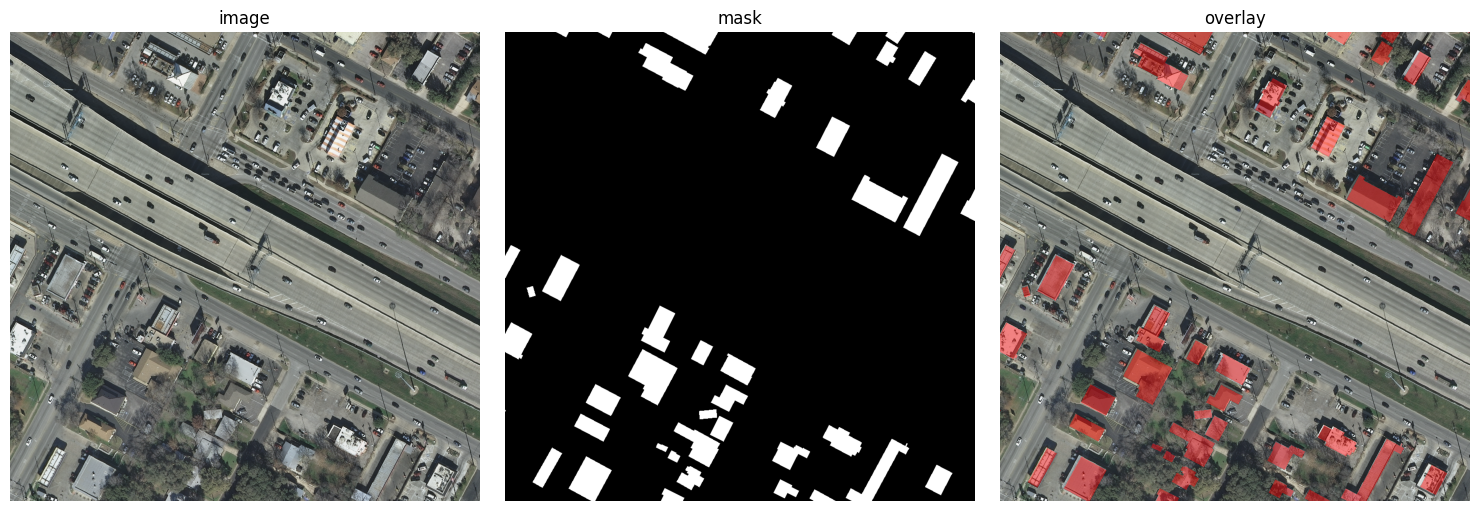

In [32]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def load(name):
    img = np.array(Image.open(train_dir / "images" / f"{name}.tif").convert("RGB"))
    msk = np.array(Image.open(train_dir / "gt" / f"{name}.tif").convert("L")) > 0
    return img, msk

img, msk = load("austin1")
print("image:", img.shape, "  mask:", msk.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img[:1000, :1000]);              axes[0].set_title("image")
axes[1].imshow(msk[:1000, :1000], cmap="gray"); axes[1].set_title("mask")
axes[2].imshow(img[:1000, :1000])
axes[2].imshow(np.ma.masked_where(~msk[:1000, :1000], msk[:1000, :1000]), cmap="autumn", alpha=0.45)
axes[2].set_title("overlay")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Building coverage

In [33]:
for name in WANT:
    _, m = load(name)
    print(f"{name:9} {100 * m.mean():5.1f}% buildings")

austin1    14.8% buildings
vienna1    18.0% buildings
austin6     8.1% buildings


## Why the split is by image

### Neighbouring tiles

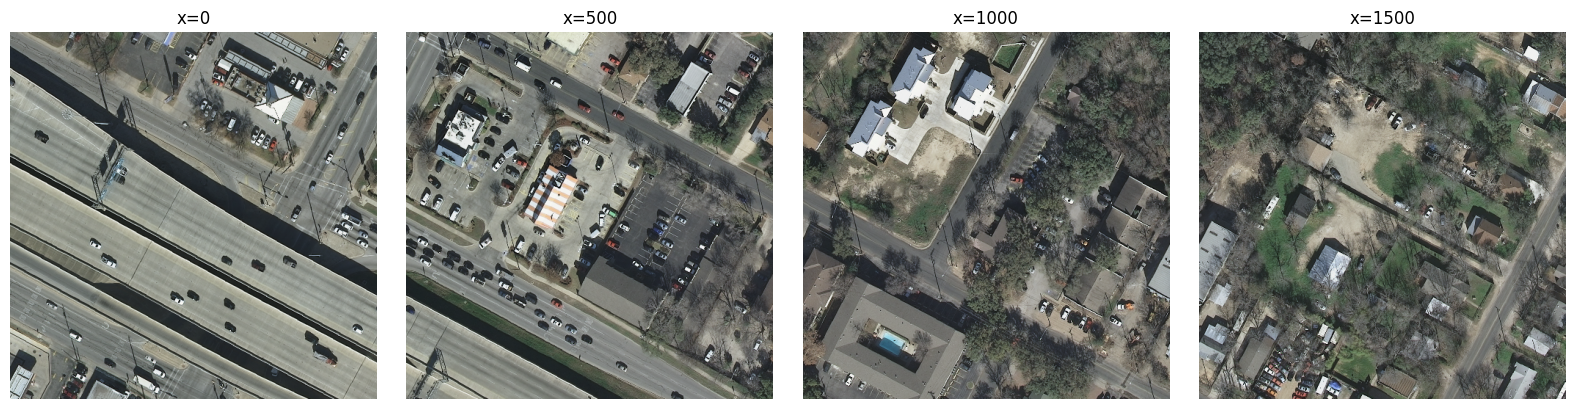

In [34]:
ts = data["tile_size"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, left in zip(axes, [0, ts, 2 * ts, 3 * ts]):
    ax.imshow(img[0:ts, left:left + ts]); ax.set_title(f"x={left}"); ax.axis("off")
plt.tight_layout(); plt.show()

### No image in two splits

In [35]:
ids = data["splits"]
assert not (set(ids["train"]) & set(ids["val"]))
assert not (set(ids["train"]) & set(ids["test"]))
assert not (set(ids["val"]) & set(ids["test"]))
print("ok")

ok
